# Fund Performance Analytics

## 1. Setup & Data Loading

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')
import os

# Load Datasets
nav_history = pd.read_csv('../data/processed/02_nav_history.csv')
fund_master = pd.read_csv('../data/processed/01_fund_master.csv')
benchmarks = pd.read_csv('../data/processed/10_benchmark_indices.csv')

# Format dates
nav_history['date'] = pd.to_datetime(nav_history['date'])
benchmarks['date'] = pd.to_datetime(benchmarks['date'])

# Ensure sorting
nav_history = nav_history.sort_values(['amfi_code', 'date']).reset_index(drop=True)
benchmarks = benchmarks.sort_values(['index_name', 'date']).reset_index(drop=True)

plt.style.use('default')
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)


## 2. Daily Returns

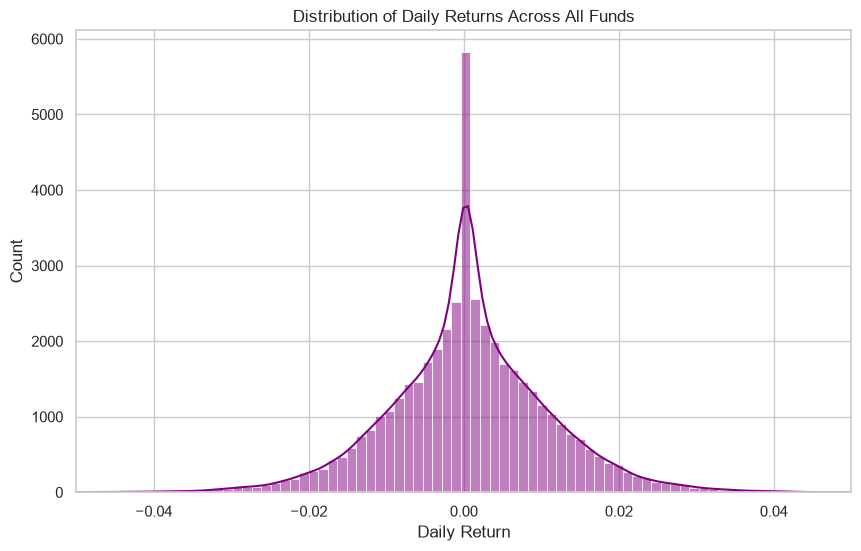

In [2]:

# Compute daily returns for all schemes
nav_history['daily_return'] = nav_history.groupby('amfi_code')['nav'].pct_change()

plt.figure(figsize=(10,6))
sns.histplot(nav_history['daily_return'].dropna(), bins=100, color='purple', kde=True)
plt.title('Distribution of Daily Returns Across All Funds')
plt.xlabel('Daily Return')
plt.xlim(-0.05, 0.05)
plt.show()


## 3. CAGR Calculation (1yr and 3yr)

In [3]:

# Compute 1yr and 3yr CAGR
max_date = nav_history['date'].max()
date_1yr_ago = max_date - pd.DateOffset(years=1)
date_3yr_ago = max_date - pd.DateOffset(years=3)

def get_closest_nav(df, target_date):
    past_navs = df[df['date'] <= target_date]
    if past_navs.empty: return np.nan
    return past_navs.iloc[-1]['nav']

results = []
for amfi, group in nav_history.groupby('amfi_code'):
    nav_end = group.iloc[-1]['nav']
    nav_1yr = get_closest_nav(group, date_1yr_ago)
    nav_3yr = get_closest_nav(group, date_3yr_ago)
    
    cagr_1yr = (nav_end / nav_1yr) - 1 if pd.notnull(nav_1yr) else np.nan
    cagr_3yr = (nav_end / nav_3yr)**(1/3) - 1 if pd.notnull(nav_3yr) else np.nan
    
    results.append({'amfi_code': amfi, 'cagr_1yr': cagr_1yr, 'cagr_3yr': cagr_3yr})

perf_metrics = pd.DataFrame(results)
perf_metrics = pd.merge(perf_metrics, fund_master[['amfi_code', 'scheme_name', 'expense_ratio_pct']], on='amfi_code')


## 4. Sharpe & Sortino Ratios

In [4]:

# Compute Sharpe & Sortino Ratio
Rf = 0.065 # 6.5% RBI repo rate proxy

risk_results = []
for amfi, group in nav_history.groupby('amfi_code'):
    rets = group['daily_return'].dropna()
    if len(rets) < 252:
        continue
    
    ann_ret = rets.mean() * 252
    ann_vol = rets.std() * np.sqrt(252)
    sharpe = (ann_ret - Rf) / ann_vol
    
    neg_rets = rets[rets < 0]
    downside_vol = neg_rets.std() * np.sqrt(252)
    sortino = (ann_ret - Rf) / downside_vol if downside_vol > 0 else np.nan
    
    risk_results.append({'amfi_code': amfi, 'sharpe_ratio': sharpe, 'sortino_ratio': sortino})

risk_df = pd.DataFrame(risk_results)
perf_metrics = pd.merge(perf_metrics, risk_df, on='amfi_code', how='left')


## 5. Alpha & Beta Computation

In [5]:

# Alpha and Beta using Nifty 100
nifty100 = benchmarks[benchmarks['index_name'] == 'NIFTY100'].copy()
nifty100['bm_return'] = nifty100['close_value'].pct_change()

alpha_beta_res = []
for amfi, group in nav_history.groupby('amfi_code'):
    merged = pd.merge(group[['date', 'daily_return']], nifty100[['date', 'bm_return']], on='date').dropna()
    if len(merged) > 100:
        slope, intercept, r_value, p_value, std_err = stats.linregress(merged['bm_return'], merged['daily_return'])
        alpha = intercept * 252
        beta = slope
        alpha_beta_res.append({'amfi_code': amfi, 'alpha': alpha, 'beta': beta})

ab_df = pd.DataFrame(alpha_beta_res)
perf_metrics = pd.merge(perf_metrics, ab_df, on='amfi_code', how='left')

ab_out = pd.merge(ab_df, fund_master[['amfi_code', 'scheme_name']], on='amfi_code')
ab_out[['amfi_code', 'scheme_name', 'alpha', 'beta']].to_csv('../reports/alpha_beta.csv', index=False)


## 6. Maximum Drawdown

In [6]:

# Maximum Drawdown
dd_results = []
for amfi, group in nav_history.groupby('amfi_code'):
    group = group.set_index('date')
    running_max = group['nav'].cummax()
    drawdown = (group['nav'] / running_max) - 1
    max_dd = drawdown.min()
    
    if max_dd < 0:
        trough_date = drawdown.idxmin()
        peak_date = running_max.loc[:trough_date].idxmax()
        dd_results.append({'amfi_code': amfi, 'max_drawdown': max_dd})
    else:
        dd_results.append({'amfi_code': amfi, 'max_drawdown': 0})

dd_df = pd.DataFrame(dd_results)
perf_metrics = pd.merge(perf_metrics, dd_df, on='amfi_code', how='left')


## 7. Fund Scorecard Generation

In [7]:

# Fund Scorecard Calculation
df_score = perf_metrics.copy().dropna(subset=['cagr_3yr', 'sharpe_ratio', 'alpha', 'max_drawdown', 'expense_ratio_pct'])

def calc_points(series, higher_is_better=True):
    N = len(series)
    ranks = series.rank(ascending=not higher_is_better, method='min') 
    return (N - ranks) / (N - 1) * 100

df_score['cagr_3yr_pts'] = calc_points(df_score['cagr_3yr'], True)
df_score['sharpe_pts'] = calc_points(df_score['sharpe_ratio'], True)
df_score['alpha_pts'] = calc_points(df_score['alpha'], True)
df_score['expense_pts'] = calc_points(df_score['expense_ratio_pct'], False) 
df_score['maxdd_pts'] = calc_points(df_score['max_drawdown'], True)

df_score['composite_score'] = (
    0.30 * df_score['cagr_3yr_pts'] +
    0.25 * df_score['sharpe_pts'] +
    0.20 * df_score['alpha_pts'] +
    0.15 * df_score['expense_pts'] +
    0.10 * df_score['maxdd_pts']
)

df_score['final_rank'] = df_score['composite_score'].rank(ascending=False).astype(int)
df_score = df_score.sort_values('final_rank')

df_score.to_csv('../reports/fund_scorecard.csv', index=False)
display(df_score[['scheme_name', 'composite_score', 'final_rank']].head(10))


,scheme_name,composite_score,final_rank
34,Mirae Asset Large Cap Fund - Regular - Growth,85.897436,1
25,ICICI Pru Midcap Fund - Regular - Growth,81.794872,2
30,Kotak Flexicap Fund - Regular - Growth,81.538462,3
2,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,80.641026,4
24,ICICI Pru Bluechip Fund - Direct - Growth,79.487179,5
16,Axis Midcap Fund - Regular - Growth,76.794872,6
19,SBI Bluechip Fund - Regular Plan - Growth,74.358974,7
36,Mirae Asset Tax Saver Fund - Regular - Growth,73.205128,8
3,ABSL Frontline Equity Fund - Regular - Growth,67.564103,9
21,SBI Small Cap Fund - Regular Plan - Growth,66.538462,10


## 8. Benchmark Comparison Chart

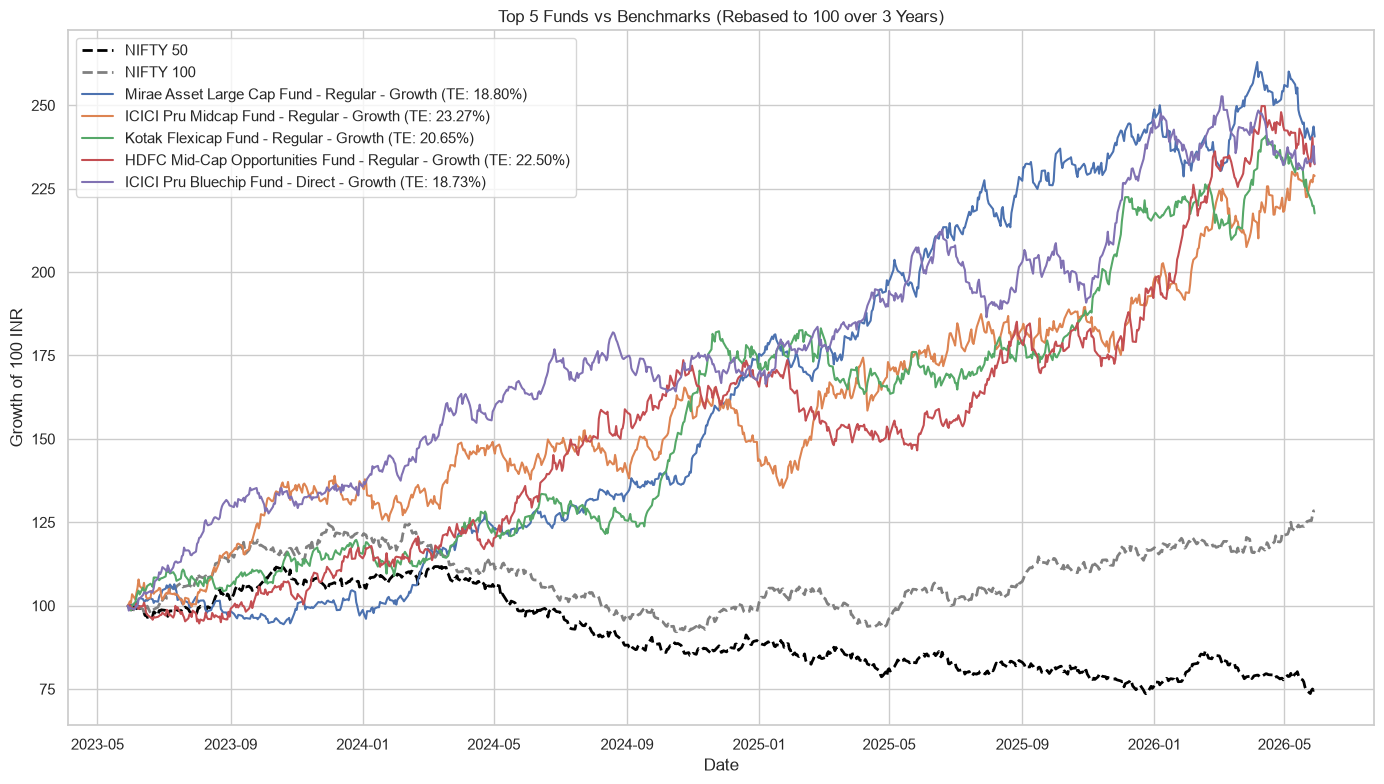

In [8]:

# Benchmark Comparison Chart for Top 5 Funds
top_5_amfi = df_score['amfi_code'].head(5).tolist()

plt.figure(figsize=(14,8))

start_date = date_3yr_ago

nifty50 = benchmarks[(benchmarks['index_name'] == 'NIFTY50') & (benchmarks['date'] >= start_date)].copy()
nifty100 = benchmarks[(benchmarks['index_name'] == 'NIFTY100') & (benchmarks['date'] >= start_date)].copy()

# Ensure we have returns to calculate tracking error later
nifty100['bm_return'] = nifty100['close_value'].pct_change()

if not nifty50.empty:
    nifty50['rebased'] = nifty50['close_value'] / nifty50['close_value'].iloc[0] * 100
    plt.plot(nifty50['date'], nifty50['rebased'], label='NIFTY 50', color='black', linewidth=2, linestyle='--')

if not nifty100.empty:
    nifty100['rebased'] = nifty100['close_value'] / nifty100['close_value'].iloc[0] * 100
    plt.plot(nifty100['date'], nifty100['rebased'], label='NIFTY 100', color='grey', linewidth=2, linestyle='--')

for amfi in top_5_amfi:
    fund_data = nav_history[(nav_history['amfi_code'] == amfi) & (nav_history['date'] >= start_date)].copy()
    if not fund_data.empty:
        fund_data['rebased'] = fund_data['nav'] / fund_data['nav'].iloc[0] * 100
        scheme_name = fund_master[fund_master['amfi_code'] == amfi]['scheme_name'].iloc[0]
        
        merged = pd.merge(fund_data[['date', 'daily_return']], nifty100[['date', 'bm_return']], on='date').dropna()
        te = (merged['daily_return'] - merged['bm_return']).std() * np.sqrt(252)
        
        plt.plot(fund_data['date'], fund_data['rebased'], label=f'{scheme_name} (TE: {te:.2%})')

plt.title('Top 5 Funds vs Benchmarks (Rebased to 100 over 3 Years)')
plt.ylabel('Growth of 100 INR')
plt.xlabel('Date')
plt.legend()
plt.tight_layout()
plt.savefig('../reports/benchmark_comparison.png', dpi=300)
plt.show()
